# 02 - Cost-Matrix Analysis

The centerpiece of this project: pick the operating threshold by minimizing expected cost, not by defaulting to 0.5 or maximizing F1. This notebook walks through the cost values, why costing is done per *episode* rather than per row, a real bug that costing decision caught, and the resulting threshold.

See `src/cost_threshold.py` for the implementation and `PLAN.md` for the full narrative.


In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.train import load_training_table, time_split, train_main_model, _with_proba, MAIN_MODEL_FEATURE_COLUMNS, TARGET_COLUMN
from src.cost_threshold import COST_MISSED_WARNING, COST_FALSE_ALARM, FALSE_ALARM_MAX_HOURS, expected_cost, select_threshold, _contiguous_run_ids

plt.rcParams["figure.figsize"] = (8, 4.5)


## The cost values

- **Missed warning: £30,000**, charged once per missed episode. This is the ABI's reported 2025 average UK domestic flood claim (up 60% year-on-year) -- a real, sourced figure, not a guess.
- **False alarm: £100**, charged once per contiguous false-alarm episode (capped at 24h -- more on why below). No authoritative published figure exists for this (it's internal underwriting-ops cost, never disclosed) -- stated here as an assumption, roughly 1-2 hours of an analyst reviewing a flagged station.

That's a 300:1 cost ratio per episode. Intuition says the model should flag liberally. The threshold search below shows that intuition is wrong once you account for *volume*.


## Why episodes, not rows

The label is per station-hour ("a warning will fire within the next 24h"), so a real event shows up as a *run* of consecutive positive rows, not one row. Costing a miss per row would charge the same event's cost once per hour it spans -- up to 24x overstatement for a single real flood.

The same logic applies to false alarms, with a twist. A short synthetic example:


In [2]:
demo = pd.DataFrame({
    "station_id": ["A"] * 6 + ["B"] * 6,
    "date_time": list(pd.date_range("2020-01-01", periods=6, freq="h")) * 2,
    "label":     [0, 0, 1, 1, 1, 0,   0, 1, 1, 0, 0, 0],
    "proba":     [0.1, 0.2, 0.6, 0.05, 0.9, 0.1,   0.2, 0.1, 0.1, 0.8, 0.8, 0.1],
})
demo


,station_id,date_time,label,proba
0,A,2020-01-01 00:00:00,0,0.10
1,A,2020-01-01 01:00:00,0,0.20
2,A,2020-01-01 02:00:00,1,0.60
3,A,2020-01-01 03:00:00,1,0.05
4,A,2020-01-01 04:00:00,1,0.90
5,A,2020-01-01 05:00:00,0,0.10
6,B,2020-01-01 00:00:00,0,0.20
7,B,2020-01-01 01:00:00,1,0.10
8,B,2020-01-01 02:00:00,1,0.10
9,B,2020-01-01 03:00:00,0,0.80


In [3]:
cost = expected_cost(demo.sort_values(["station_id", "date_time"]).reset_index(drop=True), "proba", 0.5)
print(f"expected cost at threshold 0.5: GBP{cost:,}")
print("station A's episode (rows 2-4) is caught by row 4 (proba 0.9 >= 0.5) -> no miss charged")
print("station B's episode (rows 7-8) is missed entirely -> GBP30,000")
print("station B's false alarm (rows 9-10, both proba 0.8) is ONE contiguous run -> GBP100 once, not GBP200")


expected cost at threshold 0.5: GBP30,100
station A's episode (rows 2-4) is caught by row 4 (proba 0.9 >= 0.5) -> no miss charged
station B's episode (rows 7-8) is missed entirely -> GBP30,000
station B's false alarm (rows 9-10, both proba 0.8) is ONE contiguous run -> GBP100 once, not GBP200


## The loophole this caught

An earlier version of this costing charged missed events per episode but false alarms *per row*. That seemed reasonable until `station_id` was added as a model feature (see `03_model_development.ipynb`) -- the model learned a persistent per-station bias strong enough that, for one station, its predicted probability barely dipped below the search threshold for the *entire test period*: one contiguous false-alarm run of roughly 18,000 hours, charged only once under row-level costing that let the "optimizer" pick a near-zero threshold and flag almost everything.

That's not how alert fatigue actually works -- a station stuck permanently flagged "high risk" for a year is arguably worse for an underwriting team than periodic alerts, not free. The fix: cap a false-alarm episode at 24h (the same natural unit as the label's own lookback window), so a persistently-wrong station keeps incurring cost rather than getting a one-time discount. `_contiguous_run_ids(..., max_run_length=24)` in `src/cost_threshold.py` implements this.


## The real threshold search

In [4]:
table = load_training_table("../data/processed/training_table.parquet")
train, val, test = time_split(table)
model = train_main_model(train, val)

val_scored = _with_proba(model, val, MAIN_MODEL_FEATURE_COLUMNS)
result = select_threshold(val_scored, "proba")
print(f"cost-optimal threshold (validation): {result['best_threshold']:.3f}")
print(f"expected cost at that threshold: GBP{result['expected_cost']:,.0f}")


cost-optimal threshold (validation): 0.960
expected cost at that threshold: GBP596,100


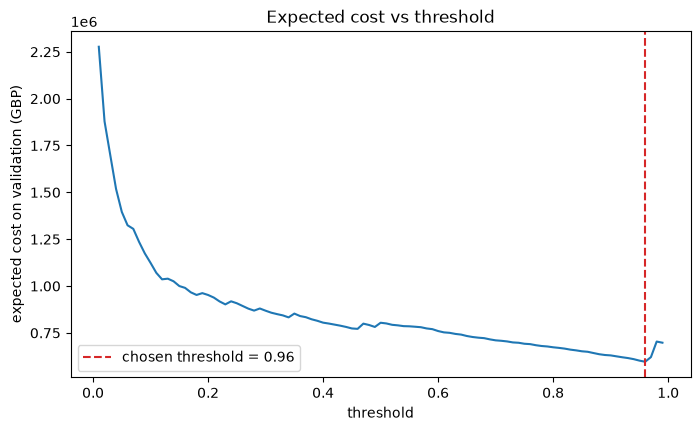

In [5]:
curve = result["curve"]
fig, ax = plt.subplots()
ax.plot(curve["threshold"], curve["expected_cost"])
ax.axvline(result["best_threshold"], color="tab:red", linestyle="--", label=f"chosen threshold = {result['best_threshold']:.2f}")
ax.set_xlabel("threshold"); ax.set_ylabel("expected cost on validation (GBP)")
ax.set_title("Expected cost vs threshold")
ax.legend()
plt.show()


The curve falls steeply as the threshold rises from 0 -- at low thresholds, false alarms (each cheap individually) accumulate across millions of hourly decision points across 132 stations and dominate the total cost, even at a 300:1 per-episode cost ratio favoring recall. That's the volume effect: it takes a high threshold before false-alarm volume drops enough for the missed-event cost to matter more. This is why the final operating point is conservative -- a genuine finding about what per-decision-point cost economics does to an alerting policy, not a modeling shortcoming.


## Applying the threshold to the held-out test set

In [6]:
threshold = result["best_threshold"]
test_scored = _with_proba(model, test, MAIN_MODEL_FEATURE_COLUMNS)
test_cost = expected_cost(test_scored, "proba", threshold)

test_sorted = test_scored.sort_values(["station_id", "date_time"]).reset_index(drop=True)
test_sorted["flagged"] = test_sorted["proba"] >= threshold
event_run_id = _contiguous_run_ids(test_sorted.assign(is_label=test_sorted["label"].astype(bool)), "is_label")
event_flagged = test_sorted.loc[event_run_id.notna()].groupby(event_run_id[event_run_id.notna()])["flagged"].any()

print(f"test expected cost at threshold {threshold:.2f}: GBP{test_cost:,.0f}")
print(f"test episodes caught: {event_flagged.sum()} / {len(event_flagged)}")


test expected cost at threshold 0.96: GBP362,600
test episodes caught: 4 / 15
